# 04 — Ranking dies before cooldown

**Question.** A wafer has a few hundred dies, each carrying one 23-qubit chip. Every junction's resistance can be measured at
room temperature in minutes. A cooldown takes days. Which dies should we cool first to find the collision-free chips fastest?
And **how accurate must the room-temperature prediction be before ranking is worth doing?**

**The key physics.** Every collision condition in Hertzberg et al.'s Table 1 compares qubits *on the same chip*.
A frequency error shared by the whole die barely changes collisions. Examples are a wafer trend, a die offset, or a wrong T_c.
(An exactly additive shift cannot change them at all. A shared change in Rn or T_c also squeezes every gap on the chip by
about half the fractional change, against an anharmonicity that does not move; that matters only for conditions sitting
within a few MHz of a collision window edge. See Experiment 5.)
Only the **within-die, per-qubit** part of the error matters. We therefore report the residual as two numbers:
a within-die per-qubit part (MHz; drives collisions) and a die-shared part (MHz; drives absolute error only).
Kreikebaum et al. ([arXiv:1909.09165](https://arxiv.org/abs/1909.09165), Supercond. Sci. Technol. 33, 06LT02 (2020)) report both halves of this picture:
* *Local is smaller than global* (Table 1): junction σIc/⟨Ic⟩ within 1 × 1 cm windows is 1.7–2.1%, against 3.1–3.8% across the wafer.
* *Relative detunings are predictable* (Supplementary material, Sec. S2 and Table S1): on two 8-qubit chips, room-temperature
  predictions were offset from the cryo frequencies by −2.62% and +0.38% on average, a chip-wide shift.
  But the per-qubit scatter of those differences was only 0.50% and 0.40%, "< 0.5%" in their words, which lets them conclude
  "relative detunings between qubit pairs can be accurately predicted with room temperature probing".
  At their 5.7–5.8 GHz that per-qubit scatter is about 23–29 MHz, inside the range we scan below.

**Scope.** We rank dies from *measured* data. The chip design is fixed. The collision checker only scores
predictions for measured dies; it is never used to choose or optimise a design.

## The chip: we combine two papers

* **Chip and collision rules (IBM):** the heavy-hex d = 3 chip from Hertzberg et al. 2021, Supplementary Fig. 3,
  with fixed set-points **5.00 / 5.07 / 5.14 GHz** (the example in their Discussion) and the Table 1 collision windows,
  which assume anharmonicity α = −330 MHz.
* **Room temperature → frequency (Fraunhofer):** Eq. 1 of Mayer, Weber et al. 2025 with the fitted T_c = 0.71 K (Lang et al. 2025).
* **C_q chosen so the anharmonicity matches Hertzberg's α = −330 MHz (derived).** We find it by exact diagonalisation
  at 5.07 GHz. It is not a published capacitance.

This is an **IBM-style 5.0–5.14 GHz chip**, not Fraunhofer's 4.42 GHz chip.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yieldkit.physics import charging_energy, H_PLANCK
from yieldkit.scenario import (make_scenario, wafer_config, RN_RSD_AS_FAB, RN_RSD_TRIMMED,
                               RESID_IBM_HZ, RESID_FRAUNHOFER_REL, F1_HZ, STEP_HZ)
from yieldkit.wafer import make_wafer
from yieldkit.evaluate import evaluate_wafer, capture_curve

sc = make_scenario()
print(f"Derived Cq = {sc.cq_f*1e15:.1f} fF  ->  EC/h = {charging_energy(sc.cq_f)/H_PLANCK/1e6:.0f} MHz "
      f"(the shortcut α ≈ −EC would have suggested ~59 fF)")
for f in sorted(set(sc.design_hz)):
    print(f"  set-point {f/1e9:.2f} GHz -> Rn target {sc.rn_target_ohm[sc.design_hz == f][0]/1e3:.3f} kΩ "
          f"({(sc.design_hz == f).sum()} qubits)")

F_MID = F1_HZ + STEP_HZ
RESID_075_HZ = 0.0075 * F_MID
RESID_FH_HZ = RESID_FRAUNHOFER_REL * F_MID
print(f"Residual presets: IBM 14.5 MHz | 0.75% = {RESID_075_HZ/1e6:.0f} MHz | Fraunhofer 1.6% = {RESID_FH_HZ/1e6:.0f} MHz")

def run(rsd, resid_q, resid_d=0.0, k=10, seeds=range(10), tc=(0.71,)):
    rows = []
    for s in seeds:
        obs, tr = make_wafer(wafer_config(sc, rsd, resid_q, resid_d, tc_true_k=tc, n_cooled_dies=k), seed=s)
        r = evaluate_wafer(obs, tr, sc, seed=s); r.pop("_orders"); r.pop("_good")
        rows.append(r)
    return pd.DataFrame(rows)

Derived Cq = 68.1 fF  ->  EC/h = 284 MHz (the shortcut α ≈ −EC would have suggested ~59 fF)
  set-point 5.00 GHz -> Rn target 6.859 kΩ (5 qubits)
  set-point 5.07 GHz -> Rn target 6.681 kΩ (5 qubits)
  set-point 5.14 GHz -> Rn target 6.509 kΩ (13 qubits)
Residual presets: IBM 14.5 MHz | 0.75% = 38 MHz | Fraunhofer 1.6% = 81 MHz


## Setup of the experiments

* **Wafer:** the Step 2 geometry: 370 dies of 10 × 7 mm, 4 mm edge exclusion (assumption), and the same spatial model
  (50/25/25 trend/die/junction split, which is an assumption). Each qubit's resistance is centred on its own target.
* **Rn spread presets:** **2% as fabricated** (as cited by Križan et al. 2026) and **0.5% after trimming**
  (Wang et al., Rigetti, arXiv:2608.27789, parallel ABAA).
* **Probe noise:** 0.1%, from Hertzberg et al.'s statement that Rn is "measurable to better than 0.1%". Cryo measurement noise is 100 kHz (Hertzberg).
* **Residual:** a real frequency deviation that room-temperature data cannot see. It includes capacitance scatter, as Mayer et al.'s footnote 2 justifies.
* **k = 10 calibration dies** by default, chosen at random. Ranking covers the remaining dies. 10 seeds per point.
* **Metrics:** *gain* = (AUC − AUC_random)/(AUC_oracle − AUC_random) of the capture curve (0 = random, 1 = oracle),
  and *cooldowns needed for 5 good chips*.

## Experiment 1 — the residual sweep (the headline question)

**Expected, stated in advance** (written in the design note before any Step 4 code existed):
* At Fraunhofer's 1.6% (≈ 81 MHz) almost no chip is collision-free, so ranking cannot help and trimming must come first.
* The sweet spot is a small residual, about IBM's 14.5 MHz, on top of a large *visible* spread.

In [2]:
residuals = [0, 5e6, 10e6, RESID_IBM_HZ, 20e6, 30e6, RESID_075_HZ, RESID_FH_HZ]
sweep = []
for label, rsd in [("as-fab 2%", RN_RSD_AS_FAB), ("trimmed 0.5%", RN_RSD_TRIMMED)]:
    for r in residuals:
        d = run(rsd, r)
        sweep.append(dict(preset=label, resid_mhz=r / 1e6, base_yield_pct=100 * d.base_yield.mean(),
                          good_dies=d.n_good.mean(), sigma_q_est_mhz=d.sigma_qubit_est_mhz.mean(),
                          gain_ours=d.gain_ours.mean(), gain_ours_sd=d.gain_ours.std(), gain_naive=d.gain_naive.mean(),
                          cool5_ours=d.cool_ours.mean(), cool5_naive=d.cool_naive.mean(), cool5_random=d.cool_random.mean()))
sweep = pd.DataFrame(sweep)
sweep.round(2)

,preset,resid_mhz,base_yield_pct,good_dies,sigma_q_est_mhz,gain_ours,gain_ours_sd,gain_naive,cool5_ours,cool5_naive,cool5_random
0,as-fab 2%,0.00,6.86,24.7,2.68,0.93,0.02,0.13,6.00,31.20,71.90
1,as-fab 2%,5.00,6.03,21.7,5.64,0.82,0.06,0.10,10.30,58.00,82.37
2,as-fab 2%,10.00,4.50,16.2,10.27,0.71,0.10,0.03,14.60,97.20,110.14
3,as-fab 2%,14.50,4.06,14.6,14.64,0.61,0.06,0.18,26.60,72.50,127.54
4,as-fab 2%,20.00,2.06,7.4,20.04,0.56,0.15,0.07,88.33,193.78,216.87
5,as-fab 2%,30.00,0.86,3.1,29.93,0.54,0.29,-0.06,205.67,318.00,286.51
6,as-fab 2%,38.02,0.25,0.9,37.89,0.48,0.44,-0.51,NaN,NaN,NaN
7,as-fab 2%,81.12,0.00,0.0,80.72,NaN,NaN,NaN,NaN,NaN,NaN
8,trimmed 0.5%,0.00,93.94,338.2,2.68,0.83,0.05,0.12,5.00,5.00,5.32
9,trimmed 0.5%,5.00,84.33,303.6,5.64,0.44,0.07,0.06,5.00,5.90,5.93


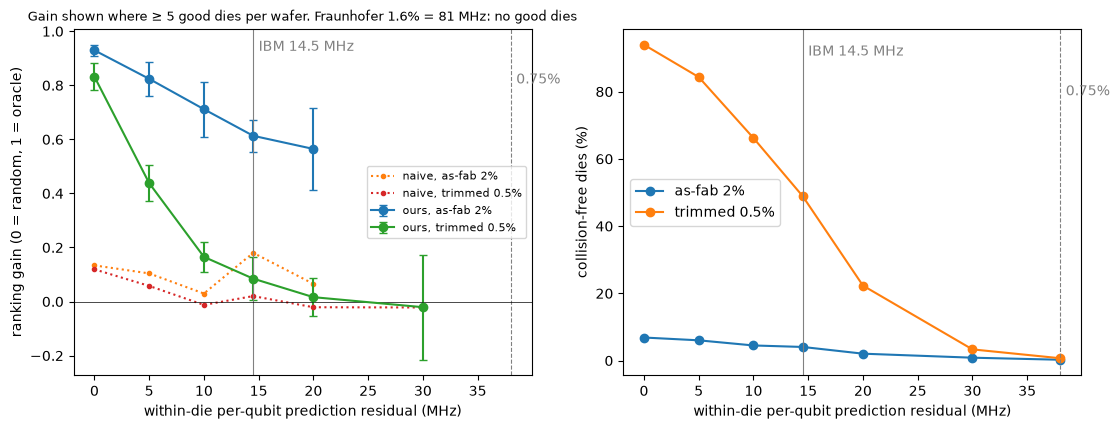

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for label, g in sweep.groupby("preset"):
    a2.plot(g[g.resid_mhz <= 40].resid_mhz, g[g.resid_mhz <= 40].base_yield_pct, marker="o", label=label)
    g = g[(g.resid_mhz <= 40) & (g.good_dies >= 5)]  # fewer than 5 good dies per wafer: gain is noise (see table)
    a1.errorbar(g.resid_mhz, g.gain_ours, yerr=g.gain_ours_sd, marker="o", capsize=3, label=f"ours, {label}")
    a1.plot(g.resid_mhz, g.gain_naive, ":", marker=".", label=f"naive, {label}")
for a in (a1, a2):
    a.axvline(14.5, color="grey", lw=0.8); a.text(15, a.get_ylim()[1] * 0.92, "IBM 14.5 MHz", color="grey")
    a.axvline(RESID_075_HZ / 1e6, color="grey", lw=0.8, ls="--"); a.text(RESID_075_HZ / 1e6 + 0.5, a.get_ylim()[1] * 0.8, "0.75%", color="grey")
    a.set_xlabel("within-die per-qubit prediction residual (MHz)")
a1.axhline(0, color="k", lw=0.5); a1.set_ylabel("ranking gain (0 = random, 1 = oracle)"); a1.legend(fontsize=8)
a2.set_ylabel("collision-free dies (%)"); a2.legend()
a1.set_title(f"Gain shown where ≥ 5 good dies per wafer. Fraunhofer 1.6% = {RESID_FH_HZ / 1e6:.0f} MHz: no good dies", fontsize=9)
plt.show()

**What actually happened (compared with the expectation):**

* **As expected:** at Fraunhofer's 1.6% (81 MHz, all per-qubit) there are **0 collision-free dies** at both presets, so ranking is moot.
* **As-fab 2%:** ranking gain falls slowly: 0.93 at 0 MHz, **0.61 at IBM's 14.5 MHz**, about 0.5 at 30 MHz. At 14.5 MHz we need about **27 cooldowns to find 5 good chips, against about 128 at random** (≈ 5× fewer). But only about 4% of dies are good, below the 10–70% band.
* **Trimmed 0.5%:** yield is in the band (49% at 14.5 MHz), but **ranking barely helps: gain 0.08**. The gain halves by 5 MHz and is gone by about 15–20 MHz.
* **Not quite what we expected:** there is no single sweet spot. What decides it is the ratio of the within-die spread the probe **can see** to the residual it **cannot see**. With our assumed 25% junction-level share of the Rn variance, the visible within-die spread is about 25 MHz as fabricated and about 6 MHz after trimming. Ranking gain is near 0.5 when the residual is comparable to that visible spread. Trimming removes exactly the information ranking would use.
* **Naive ordering** (sum of \|Rn − target\|) is close to random. It penalises die-wide offsets, which barely change collisions.
* **Caveat:** the visible within-die spread depends on our variance-split assumption. Kreikebaum et al.'s numbers suggest a local share of about 20–45%. Points with fewer than 5 good dies per wafer have large error bars.

## Headline — capture curve at the most realistic preset

We use **2% as fabricated with IBM's 14.5 MHz residual**. This is a fab without trimming that predicts as well as IBM's
published f(Rn) fit. The trimmed preset has more good dies, but there ranking barely beats random (Experiment 1).

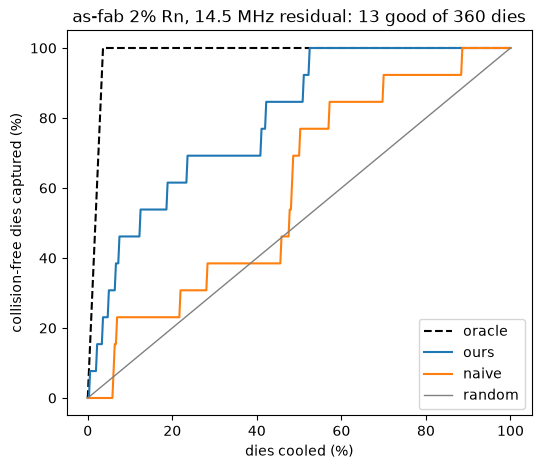

gain_ours    0.61
gain_naive   0.20
cool_ours    24.00
cool_naive   102.00
cool_random  128.93
cool_oracle  5.00


In [4]:
obs, tr = make_wafer(wafer_config(sc, RN_RSD_AS_FAB, RESID_IBM_HZ), seed=0)
r = evaluate_wafer(obs, tr, sc, seed=0)
fig, ax = plt.subplots(figsize=(6, 5))
for name, style in [("oracle", "k--"), ("ours", "C0-"), ("naive", "C1-")]:
    x, y = capture_curve(r["_orders"][name], r["_good"])
    ax.plot(100 * x, 100 * y, style, label=name)
ax.plot([0, 100], [0, 100], color="grey", lw=1, label="random")
ax.set_xlabel("dies cooled (%)"); ax.set_ylabel("collision-free dies captured (%)")
ax.set_title(f"as-fab 2% Rn, 14.5 MHz residual: {r['n_good']} good of {r['n_dies']} dies")
ax.legend()
from pathlib import Path
Path("../docs").mkdir(exist_ok=True)
fig.savefig("../docs/capture_curve.png", dpi=150, bbox_inches="tight")  # README headline figure
plt.show()
for k in ("gain_ours", "gain_naive", "cool_ours", "cool_naive", "cool_random", "cool_oracle"):
    print(f"{k:12s} {r[k]:.2f}")

## Experiment 2 — how many calibration dies?

**Expected, stated in advance:** T_c is pinned down well even by 2 dies (46 qubits), so gain should change only a little
(within about ±0.05) from k = 2 to 20. Any loss at k = 2 would come from a noisier estimate of the per-qubit residual σ.

In [5]:
ks = []
for k in (2, 5, 10, 20):
    d = run(RN_RSD_AS_FAB, RESID_IBM_HZ, k=k)
    ks.append(dict(k=k, tc_fit=d.tc_fit_k.mean(), tc_fit_sd=d.tc_fit_k.std(), sigma_q_est_mhz=d.sigma_qubit_est_mhz.mean(),
                   sigma_q_est_sd=d.sigma_qubit_est_mhz.std(), gain_ours=d.gain_ours.mean(), gain_sd=d.gain_ours.std(),
                   cool5_ours=d.cool_ours.mean()))
pd.DataFrame(ks).round(4)

,k,tc_fit,tc_fit_sd,sigma_q_est_mhz,sigma_q_est_sd,gain_ours,gain_sd,cool5_ours
0,2,0.7099,0.0007,14.7197,1.6822,0.6435,0.0697,26.5
1,5,0.7099,0.0002,14.6222,1.0900,0.6171,0.0581,30.6
2,10,0.7102,0.0002,14.6383,0.7092,0.6133,0.0602,26.6
3,20,0.7100,0.0002,14.7667,0.4251,0.6023,0.0459,38.1


**What actually happened:** as expected. T_c is fitted to ±0.0007 K even from **2 dies**, and the per-qubit σ estimate tightens from ±1.7 MHz (k = 2) to ±0.4 MHz (k = 20). Ranking gain is flat at 0.60–0.64, within its seed-to-seed scatter of about ±0.06. We did *not* see a loss at k = 2. Cooldowns-to-5 jump around (26–38) because each wafer has only about 15 good dies.

## Experiment 3 — sensitivity: half of the residual is die-shared

Same total residual of 14.5 MHz, now split equally in variance: 10.3 MHz per qubit plus 10.3 MHz shared by the die.

**Expected, stated in advance:** yield and ranking gain should look like the 10 MHz per-qubit case in Experiment 1,
because the die-shared half cannot cause collisions. The absolute prediction error should stay about the same size,
and the calibration should report a non-zero die-shared part.

In [6]:
half = RESID_IBM_HZ / np.sqrt(2)
d100 = run(RN_RSD_AS_FAB, RESID_IBM_HZ)
d50 = run(RN_RSD_AS_FAB, half, half)
cols = ["base_yield", "sigma_qubit_est_mhz", "sigma_die_est_mhz", "mean_abs_error_mhz", "gain_ours", "cool_ours"]
pd.DataFrame({"100% per-qubit": d100[cols].mean(), "50% die-shared": d50[cols].mean()}).round(3)

,100% per-qubit,50% die-shared
base_yield,0.041,0.049
sigma_qubit_est_mhz,14.638,10.555
sigma_die_est_mhz,1.272,10.958
mean_abs_error_mhz,11.781,12.141
gain_ours,0.613,0.714
cool_ours,26.600,17.600


**What actually happened:** as expected. With half the residual shared by the die, yield (4.9%) and gain (0.71) match the 10 MHz per-qubit case of Experiment 1 (4.5%, 0.71). The calibration recovers the split from 10 cooled dies: **10.6 MHz per qubit and 11.0 MHz die-shared**, against 10.3 / 10.3 MHz true. The absolute prediction error is unchanged (12.1 vs 11.8 MHz). The **same total residual is less harmful when part of it is shared by the die.**

## Experiment 4 — drift: wafer 2 has true T_c = 0.68 K

Wafer 1 (T_c = 0.71 K) is calibrated on 10 dies. Wafer 2 (T_c = 0.68 K) is either ranked with **wafer 1's calibration reused**
or **recalibrated on 3 of its own dies**. Both are scored on the same uncooled dies of wafer 2.

**Expected, stated in advance:** a T_c drop from 0.71 to 0.68 K moves every frequency down by about 115 MHz at 5.07 GHz.
That is a common-mode shift, so (a) ranking gain should be about the same either way, but (b) reusing the old calibration should
leave a mean bias of roughly −115 MHz in absolute prediction, while recalibration should remove it.

In [7]:
drift = []
for s in range(10):
    obs_a, _ = make_wafer(wafer_config(sc, RN_RSD_AS_FAB, RESID_IBM_HZ, tc_true_k=(0.71,), n_cooled_dies=10), seed=s)
    from yieldkit.ranking import calibrate
    cal_a = calibrate(obs_a, sc.cq_f)
    obs_b, tr_b = make_wafer(wafer_config(sc, RN_RSD_AS_FAB, RESID_IBM_HZ, tc_true_k=(0.68,), n_cooled_dies=3), seed=100 + s)
    reuse = evaluate_wafer(obs_b, tr_b, sc, seed=s, calibration=cal_a)
    recal = evaluate_wafer(obs_b, tr_b, sc, seed=s)
    for name, r in (("reuse wafer-1 calibration", reuse), ("recalibrate on 3 dies", recal)):
        drift.append(dict(method=name, tc_used=r["tc_fit_k"], bias_mhz=r["mean_bias_mhz"],
                          gain=r["gain_ours"], cool5=r["cool_ours"]))
drift = pd.DataFrame(drift)
summary = drift.groupby("method").agg(["mean", "std"]).round(3)
summary

tc_used      bias_mhz          gain        cool5  \
                             mean  std     mean    std   mean    std  mean   
method                                                                       
recalibrate on 3 dies        0.68  0.0   -0.522  1.675  0.616  0.133  35.1   
reuse wafer-1 calibration    0.71  0.0  115.457  0.789  0.605  0.125  38.5   

                                   
                              std  
method                             
recalibrate on 3 dies      20.025  
reuse wafer-1 calibration  24.677

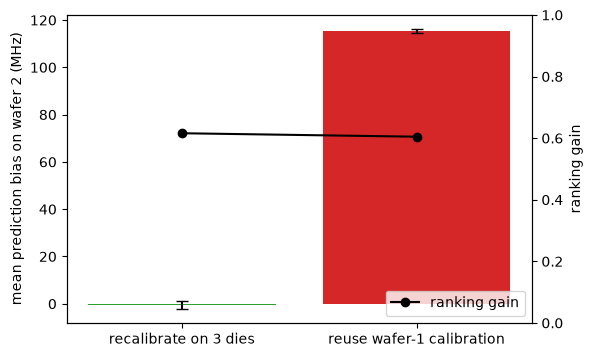

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
m = drift.groupby("method")
means = m.bias_mhz.mean()
ax.bar(range(2), means, yerr=m.bias_mhz.std(), capsize=4,
       color=["C3" if name.startswith("reuse") else "C2" for name in means.index])
ax.set_xticks(range(2)); ax.set_xticklabels(m.bias_mhz.mean().index)
ax.set_ylabel("mean prediction bias on wafer 2 (MHz)")
ax2 = ax.twinx(); ax2.plot(range(2), m.gain.mean(), "ko-", label="ranking gain"); ax2.set_ylim(0, 1); ax2.set_ylabel("ranking gain")
ax2.legend(loc="lower right"); plt.show()

**What actually happened:** the size of the shift was as expected, but the sign in our expectation was written loosely. Bias here means *predicted − true*. Reusing wafer 1's calibration predicts **115 MHz too high** (±0.8 MHz), because the real frequencies dropped by 115 MHz. Recalibrating on just **3 dies** removes the bias (−0.5 ± 1.7 MHz). **Ranking gain is unchanged** (0.61 vs 0.62), as expected: a T_c drift is almost a common-mode shift and barely changes collisions (it squeezes the gaps by about 2%, i.e. 1–3 MHz; see Experiment 5). Recalibration matters for absolute frequency (for example, matching readout resonators or a laser-trim plan), not for which dies to cool.

## Experiment 5 — more realistic effects (EC scatter and ageing)

Three effects that room-temperature data cannot see, added on top of the earlier model:

* **Capacitor (EC) scatter**, 0.8% (Osman et al., [Phys. Rev. Research 5, 043001 (2023)](https://doi.org/10.1103/PhysRevResearch.5.043001), Fig. 2(b)).
  At 5.07 GHz it moves f₀₁ by about 19 MHz per qubit (sensitivity (f − E_C)/(2f) ≈ 0.47). Each qubit's true anharmonicity
  follows its own E_C (α_q = −330 MHz × E_C,q / E_C,design, an approximation); the ranking keeps the design α.
  Osman's 0.8% was measured across 4 dies, so treating all of it as per-qubit is an upper bound; we also run a 50 / 50 split.
* **Shared ageing** between probe and cooldown: Rn +4% (Osman et al., Fig. 1(h): +4% in 21 days). The calibration dies age
  too, and the fitted T_c absorbs it.
* **Per-junction ageing**: 0 / 0.25 / 0.5 / 1% of Rn. **ASSUMED: there is no published per-junction value**; Osman et al.
  only show that the wafer spread did not change.

The "other" residual stays at IBM's 14.5 MHz. That number was measured on real chips and already contains IBM's own capacitor
scatter, so **IBM residual + Osman EC scatter is a pessimistic scenario, not a correction to IBM**. Every row is labelled
with its total per-qubit residual in MHz.

**Sanity check first: a shared Rn drift is not a pure common shift.** f + E_C/h scales as (1 + d)^(−1/2), so the gaps
between qubits shrink by about d/2, while the anharmonicity (set by the capacitor) does not move. Below, one wafer (~2% Rn,
14.5 MHz residual, seed 0) with and without 1.6% shared drift: which collision types change, and why the dies that flip do.

In [9]:
from yieldkit.collisions import count_collisions, directed_edges, spectator_triples, ALPHA_HZ, BOUND
n_q = sc.lattice.n_qubits
dirx = directed_edges(sc.lattice.edges, sc.design_hz); trip = spectator_triples(dirx, n_q)
fm = lambda t: t.sort_values(["die_id", "qubit_id"]).f01_true_hz.to_numpy().reshape(-1, n_q)
_, t_a = make_wafer(wafer_config(sc, RN_RSD_AS_FAB, RESID_IBM_HZ), seed=0)
_, t_b = make_wafer(wafer_config(sc, RN_RSD_AS_FAB, RESID_IBM_HZ, drift_shared_rel=0.016), seed=0)
ca, cb = count_collisions(fm(t_a), dirx, trip), count_collisions(fm(t_b), dirx, trip)
print("dies whose count of each collision type changed:", {t: int((ca[t] != cb[t]).sum()) for t in ca})
good_a, good_b = sum(ca.values()) == 0, sum(cb.values()) == 0
print(f"collision-free dies: {good_a.sum()} -> {good_b.sum()}")
for die in np.flatnonzero(good_a != good_b):
    print(f"  die {die}: newly hit by type(s)", [t for t in cb if cb[t][die] != ca[t][die]])

dies whose count of each collision type changed: {1: 6, 2: 69, 3: 0, 4: 0, 5: 9, 6: 0, 7: 24}
collision-free dies: 13 -> 9
  die 120: newly hit by type(s) [7]
  die 163: newly hit by type(s) [2]
  die 210: newly hit by type(s) [7]
  die 258: newly hit by type(s) [2]


All verdict flips come from **gap-versus-α conditions** (type 2: |2·gap + α| < 4 MHz; type 7: |2f_j + α − f_i − f_k| < 17 MHz)
that started within 1–3 MHz of a window edge. The ~2.6–3 MHz moves match a ~0.8% squeeze of a ~165 MHz gap, doubled.
So this is physics, not a bug: a shared Rn or T_c change *barely* changes collisions, but it is not exactly zero.

**Expected, stated in advance** (written in the 6c plan before any of these runs, kept exactly as written):

- **As-fab:** the gain falls from 0.61 to roughly 0.55 at 20–25 MHz and about 0.5 at 33–36 MHz. Only about 1–2% of dies are good, so many wafers will have fewer than 5 good chips.
- **Trimmed:** the gain drops to about 0. Yield falls to roughly 5–20%.
- **Overall:** the "~5×" figure will very likely shrink, and the cooldowns-to-5 metric will often be undefined on the as-fab rows.

In [10]:
from yieldkit.scenario import EC_RSD_OSMAN
from yieldkit.physics import f01_ec_sensitivity
from yieldkit.evaluate import cooldowns_to_n_good, expected_random_cooldowns

ec_j = charging_energy(sc.cq_f)
EC_PER_Q = np.sqrt(np.mean((EC_RSD_OSMAN * np.array([f01_ec_sensitivity(f, ec_j) for f in sc.design_hz]) * sc.design_hz) ** 2))
DRIFT_PER_PCT = np.sqrt(np.mean(((sc.design_hz + ec_j / H_PLANCK) / 2) ** 2)) * 0.01   # Hz of f per 1% per-junction Rn drift

def predicted_total_mhz(ec_on, ec_q_share, s_j):
    ec = EC_PER_Q * np.sqrt(ec_q_share) if ec_on else 0.0
    return np.sqrt(RESID_IBM_HZ**2 + ec**2 + (DRIFT_PER_PCT * s_j * 100) ** 2) / 1e6

def run6(rsd, ec_on, ec_q_share, s_j, drift, seeds=range(10)):
    rows = []
    for s in seeds:
        cfg = wafer_config(sc, rsd, RESID_IBM_HZ, ec_rsd=EC_RSD_OSMAN if ec_on else 0.0,
                           ec_die_frac=1 - ec_q_share, drift_shared_rel=drift, drift_junction_rsd=s_j)
        obs, tr = make_wafer(cfg, seed=s)
        r = evaluate_wafer(obs, tr, sc, seed=s)
        row = dict(base_yield=r["base_yield"], n_good=r["n_good"], sq=r["sigma_qubit_est_mhz"], sd=r["sigma_die_est_mhz"],
                   gain_ours=r["gain_ours"], gain_naive=r["gain_naive"])
        for N in (3, 5):
            row[f"c{N}_ours"] = cooldowns_to_n_good(r["_orders"]["ours"], r["_good"], N)
            row[f"c{N}_naive"] = cooldowns_to_n_good(r["_orders"]["naive"], r["_good"], N)
            row[f"c{N}_rand"] = expected_random_cooldowns(r["n_dies"], r["n_good"], N)
        rows.append(row)
    d = pd.DataFrame(rows)
    out = dict(yield_pct=100 * d.base_yield.mean(), good_dies=d.n_good.mean(), meas_sigma_q=d.sq.mean(), meas_sigma_die=d.sd.mean(),
               gain_ours=d.gain_ours.mean(), gain_naive=d.gain_naive.mean())
    for N in (3, 5):
        ok = d[f"c{N}_ours"].notna()
        out[f"N{N}: wafers <{N} good"] = int((~ok).sum())
        for m in ("ours", "naive", "rand"):
            out[f"N{N} {m}"] = d.loc[ok, f"c{N}_{m}"].mean() if ok.any() else np.nan
    return out

runs = []
for preset, rsd in [("as-fab 2%", RN_RSD_AS_FAB), ("trimmed 0.5%", RN_RSD_TRIMMED)]:
    runs.append(dict(preset=preset, ec="none", ec_q_share=1.0, s_j=0.0, drift=0.0, ec_on=False, label="R: Step 4 reference"))
    runs.append(dict(preset=preset, ec="100% per-qubit", ec_q_share=1.0, s_j=0.0, drift=0.0, ec_on=True, label="check: shared drift 0%"))
    for share, name in [(1.0, "100% per-qubit"), (0.5, "50 / 50")]:
        for s_j in (0.0, 0.0025, 0.005, 0.01):
            runs.append(dict(preset=preset, ec=name, ec_q_share=share, s_j=s_j, drift=0.04, ec_on=True, label=""))
table = []
for r in runs:
    rsd = RN_RSD_AS_FAB if r["preset"].startswith("as-fab") else RN_RSD_TRIMMED
    res = run6(rsd, r["ec_on"], r["ec_q_share"], r["s_j"], r["drift"])
    table.append({"preset": r["preset"], "EC": r["ec"], "per-junction drift %": 100 * r["s_j"], "shared drift %": 100 * r["drift"],
                  "note": r["label"], "pred total per-qubit resid (MHz)": predicted_total_mhz(r["ec_on"], r["ec_q_share"], r["s_j"]), **res})
exp5 = pd.DataFrame(table)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
exp5.round(2)

,preset,EC,per-junction drift %,shared drift %,note,pred total per-qubit resid (MHz),yield_pct,good_dies,meas_sigma_q,meas_sigma_die,gain_ours,gain_naive,N3: wafers <3 good,N3 ours,N3 naive,N3 rand,N5: wafers <5 good,N5 ours,N5 naive,N5 rand
0,as-fab 2%,none,0.00,0.0,R: Step 4 reference,14.50,4.06,14.6,14.64,1.27,0.61,0.18,0,12.90,32.20,76.52,0,26.60,72.50,127.54
1,as-fab 2%,100% per-qubit,0.00,0.0,check: shared drift 0%,24.09,1.08,3.9,24.02,1.51,0.38,0.10,4,93.50,154.00,176.20,5,173.20,242.80,262.15
2,as-fab 2%,100% per-qubit,0.00,4.0,,24.09,1.22,4.4,23.68,1.49,0.40,0.07,1,139.33,201.33,203.04,6,215.75,263.50,265.02
3,as-fab 2%,100% per-qubit,0.25,4.0,,25.01,1.72,6.2,24.82,1.21,0.36,-0.04,0,104.10,153.20,161.20,2,136.50,236.88,234.31
4,as-fab 2%,100% per-qubit,0.50,4.0,,27.59,0.97,3.5,27.54,1.18,0.48,0.16,3,151.43,223.14,211.81,6,158.00,248.50,279.35
5,as-fab 2%,100% per-qubit,1.00,4.0,,36.11,0.69,2.5,36.12,1.01,0.20,-0.03,4,202.67,289.33,246.68,9,317.00,336.00,300.83
6,as-fab 2%,50 / 50,0.00,4.0,,19.88,2.36,8.5,19.55,13.06,0.48,0.09,0,39.00,107.10,125.85,1,94.33,154.78,192.94
7,as-fab 2%,50 / 50,0.25,4.0,,20.99,2.11,7.6,20.82,12.37,0.44,0.13,0,52.70,104.70,132.29,0,107.00,194.40,220.48
8,as-fab 2%,50 / 50,0.50,4.0,,24.00,1.06,3.8,23.92,12.26,0.44,0.41,2,120.25,121.12,207.74,7,145.00,267.67,261.44
9,as-fab 2%,50 / 50,1.00,4.0,,33.45,0.50,1.8,33.26,11.88,0.39,0.22,7,233.67,142.33,270.75,10,NaN,NaN,NaN


**Predicted vs actual, side by side.** Predicted ranges are the advance statements above; the residual prediction is the quadrature sum.

In [11]:
pred_gain = lambda p, resid: ("~0.55" if resid <= 25.5 else "~0.5") if p.startswith("as-fab") else "~0"
pred_yield = lambda p: "~1–2%" if p.startswith("as-fab") else "~5–20%"
side = exp5[exp5.note == ""].copy()
side = pd.DataFrame({
    "preset": side.preset, "EC": side.EC, "per-junction drift %": side["per-junction drift %"],
    "resid predicted (MHz)": side["pred total per-qubit resid (MHz)"].round(1), "resid measured (MHz)": side.meas_sigma_q.round(1),
    "gain predicted": [pred_gain(p, x) for p, x in zip(side.preset, side["pred total per-qubit resid (MHz)"])],
    "gain actual": side.gain_ours.round(2),
    "yield predicted": [pred_yield(p) for p in side.preset], "yield actual %": side.yield_pct.round(1),
    "N5 ours vs random": [f"{a:.0f} vs {b:.0f}" if not np.isnan(a) else "n/a" for a, b in zip(side["N5 ours"], side["N5 rand"])],
    "wafers <5 good": side["N5: wafers <5 good"],
    "N3 ours vs random": [f"{a:.0f} vs {b:.0f}" if not np.isnan(a) else "n/a" for a, b in zip(side["N3 ours"], side["N3 rand"])],
    "wafers <3 good": side["N3: wafers <3 good"],
})
side

,preset,EC,per-junction drift %,resid predicted (MHz),resid measured (MHz),gain predicted,gain actual,yield predicted,yield actual %,N5 ours vs random,wafers <5 good,N3 ours vs random,wafers <3 good
2,as-fab 2%,100% per-qubit,0.00,24.1,23.7,~0.55,0.40,~1–2%,1.2,216 vs 265,6,139 vs 203,1
3,as-fab 2%,100% per-qubit,0.25,25.0,24.8,~0.55,0.36,~1–2%,1.7,136 vs 234,2,104 vs 161,0
4,as-fab 2%,100% per-qubit,0.50,27.6,27.5,~0.5,0.48,~1–2%,1.0,158 vs 279,6,151 vs 212,3
5,as-fab 2%,100% per-qubit,1.00,36.1,36.1,~0.5,0.20,~1–2%,0.7,317 vs 301,9,203 vs 247,4
6,as-fab 2%,50 / 50,0.00,19.9,19.5,~0.55,0.48,~1–2%,2.4,94 vs 193,1,39 vs 126,0
7,as-fab 2%,50 / 50,0.25,21.0,20.8,~0.55,0.44,~1–2%,2.1,107 vs 220,0,53 vs 132,0
8,as-fab 2%,50 / 50,0.50,24.0,23.9,~0.55,0.44,~1–2%,1.1,145 vs 261,7,120 vs 208,2
9,as-fab 2%,50 / 50,1.00,33.4,33.3,~0.5,0.39,~1–2%,0.5,n/a,10,234 vs 271,7
12,trimmed 0.5%,100% per-qubit,0.00,24.1,23.7,~0,0.03,~5–20%,11.5,40 vs 43,0,19 vs 26,0
13,trimmed 0.5%,100% per-qubit,0.25,25.0,24.8,~0,0.04,~5–20%,10.0,45 vs 50,0,26 vs 30,0


**What actually happened (compared with the advance statements):**

* **Residual:** the measured per-qubit residual matches the quadrature prediction within 0.4 MHz in every row (e.g. 24.1 MHz predicted, 23.7 MHz measured).
* **Shared 4% drift:** no effect on ranking once the same wafer's cooled dies recalibrate T_c (as-fab gain 0.38 at 0% vs 0.40 at 4%; trimmed 0.03 vs 0.03).
* **As-fab gain — lower than predicted.** Predicted ~0.55 at 20–25 MHz; actual 0.36–0.48. Predicted ~0.5 at 33–36 MHz; actual 0.20–0.39.
  It is *not* the per-qubit anharmonicity (scoring the same rankings with α fixed gives 0.40 vs 0.40). A plain 24.1 MHz residual with no EC
  and no drift gives 0.45 ± 0.12 on the same seeds, so EC scatter acts like any residual of the same size. The prediction leaned on noisy Step 4 points
  (0.56 at 20 MHz, 0.54 ± 0.27 at 30 MHz). With only ~2–8 good dies per wafer the gain scatters by ±0.1–0.3, which is also why it is not monotonic in the per-junction drift.
* **As-fab yield:** predicted ~1–2%; actual 0.5–2.4%. Roughly as expected.
* **Trimmed gain:** predicted ~0; actual 0.01–0.09. As expected.
* **Trimmed yield — partly outside the predicted 5–20%:** 10–12% with EC fully per-qubit (as expected), but 21–26% with the 50 / 50 split at ≤ 0.25% per-junction drift (above), and 1–2% at 1% per-junction drift (below).
* **The "~5×" shrinks, as expected.** With EC fully per-qubit, finding 3 good chips takes 104–151 cooldowns with ranking vs 161–212 at random (~1.4–1.5×).
  With the 50 / 50 EC split and ≤ 0.25% per-junction drift: 39–53 vs 126–132 (~2.5–3×). Cooldowns-to-5 is undefined on many as-fab wafers, as predicted:
  6, 2, 6 and 9 of 10 wafers had fewer than 5 good dies (EC fully per-qubit), 1, 0, 7 and 10 of 10 (50 / 50).
* **What it means:** with Osman-level capacitor scatter counted as per-qubit, ranking still beats random but needs 100+ cooldowns for 3 collision-free
  heavy-hex chips, because only ~1% of dies are collision-free. The bigger lever is reducing the per-qubit scatter that room-temperature data cannot see
  (capacitor, per-junction drift); how much of Osman's 0.8% is really per-qubit is the number that decides this.

## What this means for a fab

* **Measure the right error.** For choosing dies, what matters is the *within-die, per-qubit* prediction error in MHz, not the absolute error. A 115 MHz T_c drift left the ranking untouched; 3 cooled dies fix the absolute offset.
* **Ranking pays off before trimming, not after.** On an untrimmed 2% wafer with IBM-level prediction (14.5 MHz), ranking finds 5 collision-free chips in about 5× fewer cooldowns than random. After trimming to 0.5%, the remaining per-qubit error must be below about 5–10 MHz for ranking to add anything.
* **Fraunhofer-level 1.6% is the open question.** If all of it is per-qubit (≈ 81 MHz), no heavy-hex chip is collision-free. If much of it is die-shared, it is harmless for collisions. A handful of cooled dies can measure that split (Experiment 3). It is the first number to ask a partner for.

*Synthetic data shaped by published statistics; variance split, edge exclusion and residual split are our assumptions.*